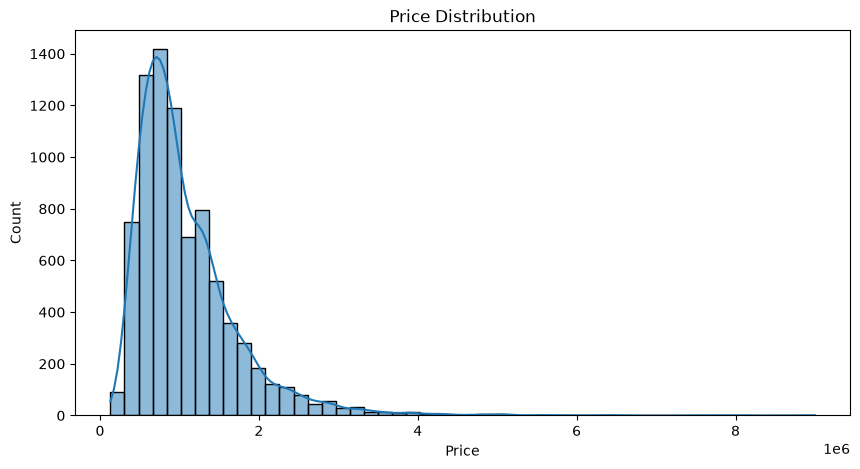

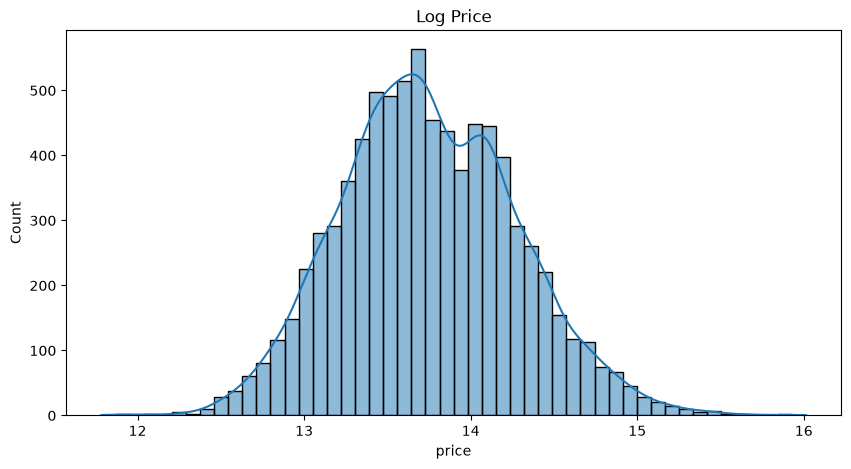

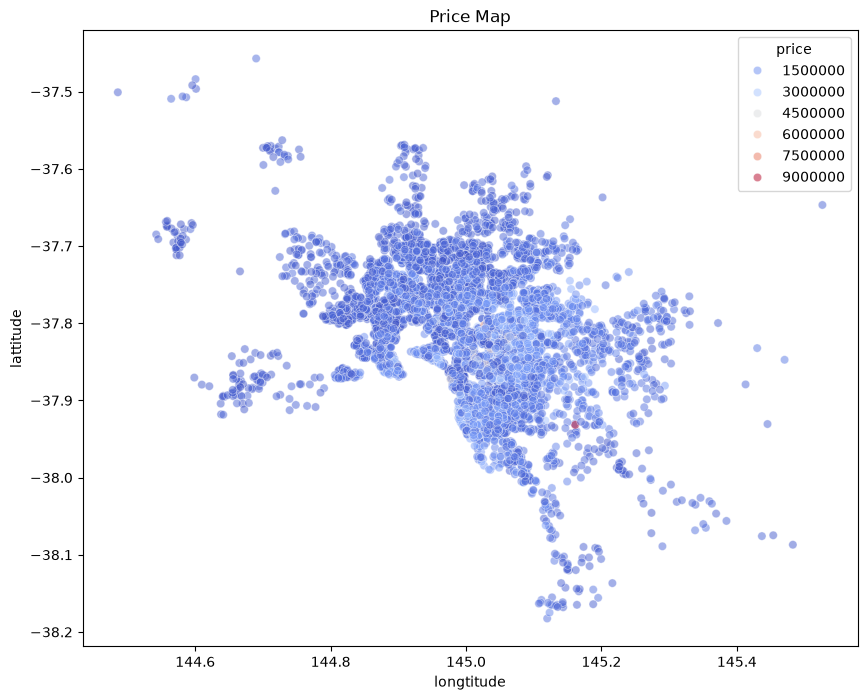

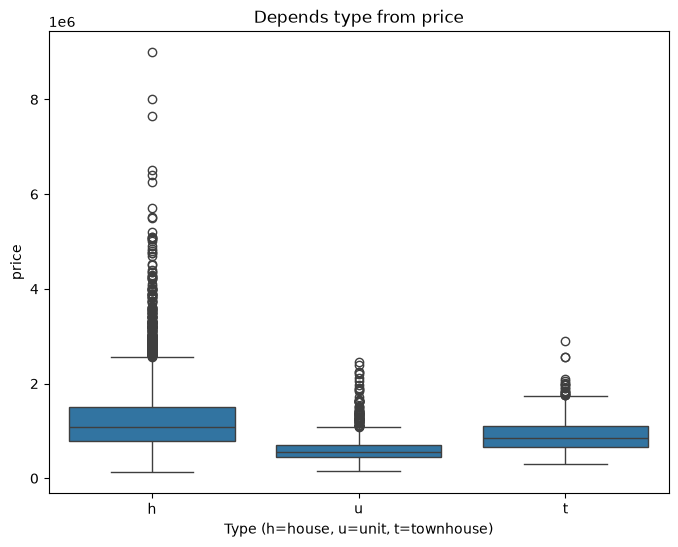

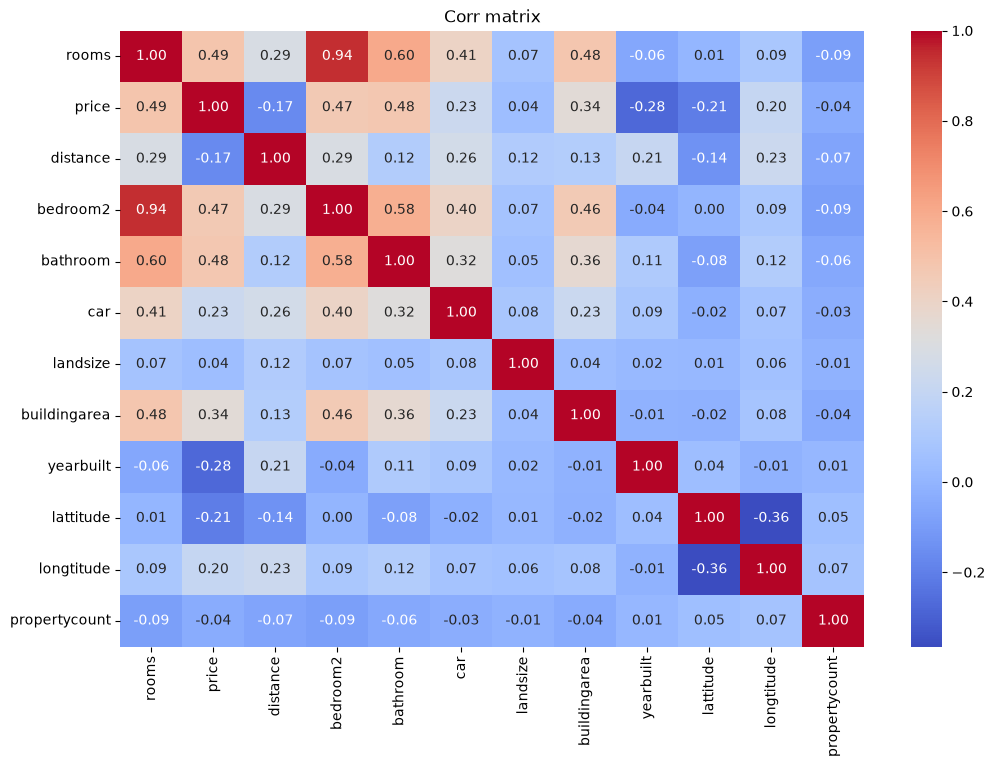

In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Data Loading and Formatting
df = pd.read_csv("data/melb_data.csv")

# Standardize column names (lowercase and snake_case)
df.columns = df.columns.str.lower().str.replace(" ", "_")

# 2. Dropping High-Cardinality and Irrelevant Features
# suburb, address, sellerg, and postcode have too many unique string values.
# Keeping them would cause massive memory issues during One-Hot Encoding and add noise.
del df["suburb"]
del df["address"]
del df["sellerg"]
del df["postcode"]
del df["date"]

# 3. Handling Missing Values 
# 'car' (62 missing): Missing likely means no parking spot available. Imputing with 0.
df['car'] = df['car'].fillna(0)

# 'buildingarea' (6450 missing): Crucial feature. 
# Imputing intelligently by taking the median building area grouped by the number of rooms.
df['buildingarea'] = df.groupby('rooms')['buildingarea'].transform(lambda x: x.fillna(x.median()))
df['buildingarea'] = df['buildingarea'].fillna(df['buildingarea'].median()) # Fallback for any remaining NaNs

# 'yearbuilt' (5375 missing): Imputing with the overall median year.
df['yearbuilt'] = df['yearbuilt'].fillna(df['yearbuilt'].median())

# 'councilarea' (1369 missing): Categorical feature with 33 unique values. 
# Filling NaNs with 'Unknown' so DictVectorizer can treat it as a separate category.
df['councilarea'] = df['councilarea'].fillna('Unknown')

# 4. Feature Engineering Notes (EDA Summary)
# - rooms, bedroom2, bathroom: Highly predictive discrete numerical features with no missing values.
# - type: Categorical feature (h=house, u=unit, t=townhouse). Excellent predictor.
# - method: Property sale method (e.g., SA, PI, S). Kept to evaluate its impact on price.
# - distance: Distance from CBD (Central Business District). Crucial float64 spatial feature.
# - Target Variable (y): 'price'

# 5. Splitting the Dataset (60% / 20% / 20%)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Resetting indices for clean DataFrames
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


plt.figure(figsize=(10, 5))
sns.histplot(df_train['price'], bins=50, kde=True)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

#log price are better
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df_train['price']), bins=50, kde=True)
plt.title('Log Price')
plt.show()

# Extracting the target variable (Price)
y_full_train = np.log1p(df_full_train['price'].values)
y_train = np.log1p(df_train['price'].values)
y_val = np.log1p(df_val['price'].values)
y_test = np.log1p(df_test['price'].values)

plt.figure(figsize=(10, 8))
sns.scatterplot(x='longtitude', y='lattitude', hue='price', 
                palette='coolwarm', data=df_train, alpha=0.5)
plt.title('Price Map')
plt.show()

plt.figure(figsize=(8, 6))
sns.boxplot(x='type', y='price', data=df_train)
plt.title('Depends type from price')
plt.xlabel('Type (h=house, u=unit, t=townhouse)')
plt.ylabel('price')
plt.show()

plt.figure(figsize=(12, 8))
numeric_df = df_train.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Corr matrix')
plt.show()

# Removing the target variable from the feature matrices
del df_full_train['price']
del df_train['price']
del df_val['price']
del df_test['price']

In [38]:
# On heat map we can see multicoreletion and we shoud drop bedroom2
df_train = df_train.drop(columns=['bedroom2'])
df_val = df_val.drop(columns=['bedroom2'])
df_test = df_test.drop(columns=['bedroom2'])

# transform yearbuilt into age
df_train['age'] = 2017 - df_train['yearbuilt']
df_val['age'] = 2017 - df_val['yearbuilt']
df_test['age'] = 2017 - df_test['yearbuilt']

df_train = df_train.drop(columns=['yearbuilt'])
df_val = df_val.drop(columns=['yearbuilt'])
df_test = df_test.drop(columns=['yearbuilt'])

In [39]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mean_squared_error
import xgboost as xgb

train_dict = df_train.to_dict(orient='records')
val_dict = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)



def train_and_evaluate(model, name = "Name", silence = False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    if not silence:
        print(f"{name} RMSE: {rmse:.4f}")
    
    return model, rmse


print("--- Baseline Models Performance ---")

lin_reg = LinearRegression()
train_and_evaluate(lin_reg, "Linear Regression")

ridge_reg = Ridge()
train_and_evaluate(ridge_reg, "Ridge Regression")

dt = DecisionTreeRegressor()
train_and_evaluate(dt, "Decision Tree")

rf = RandomForestRegressor()
train_and_evaluate(rf, "Random Forest")

xgb_model = xgb.XGBRegressor(
    eta=0.1, 
    n_estimators=100, 
    objective='reg:squarederror', 
    random_state=1,
    n_jobs=-1
)
train_and_evaluate(xgb_model, "XGBoost")
print()

--- Baseline Models Performance ---
Linear Regression RMSE: 0.3260
Ridge Regression RMSE: 0.3274
Decision Tree RMSE: 0.2831
Random Forest RMSE: 0.1997
XGBoost RMSE: 0.1927



In [40]:
#ridge_reg_params
max_iter = [10, 20, 30, 40, 50, None]
alpha = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 100, 1000, 10000]
best_params = {}
min_rmse = 100
for m in max_iter:
    for a in alpha:
        lin_reg_tune = Ridge(alpha=a, max_iter=m, random_state=1)
        _, rmse = train_and_evaluate(lin_reg_tune, "Ridge", silence=True)
        if rmse<min_rmse:
            min_rmse = rmse
            best_params = {"max_iter": m, "alpha": a}
print(best_params)
print(min_rmse)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


{'max_iter': 10, 'alpha': 1e-05}
0.3259764568054626


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.404147624671009e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


In [41]:
# Decision Tree Regressor tune
max_depth = [5, 10, 15, 20, 25]
min_samples_lefs = [2, 4, 5, 6, 10, 15, 20, 25, 30]
min_samples_split = [2, 4, 5]
best_params2 = {}
min_rmse2 = 100

for d in max_depth:
    for l in min_samples_lefs:
        for s in min_samples_split: 
            dt_tune = DecisionTreeRegressor(max_depth=d, min_samples_leaf=l, min_samples_split=s, random_state=1)
            _, rmse = train_and_evaluate(dt_tune, "Decision Tree", silence=True)
            if rmse<min_rmse2:
                min_rmse2 = rmse
                best_params2 = {"max_depth": d, "min_samples_lefs": l, "min_samples_split":s}
print(best_params2)
print(min_rmse2)

{'max_depth': 20, 'min_samples_lefs': 15, 'min_samples_split': 2}
0.2422945336266657


In [42]:
# Random Forest Tune
n_estimators = [50, 100, 150, 200, 250]
max_depth = [20, 25, 30]

best_params3 = {}
min_rmse3 = 100

for e in n_estimators:
    for d in max_depth:
        rf_tune = RandomForestRegressor(n_estimators=e, max_depth=d, min_samples_split=2, min_samples_leaf=2, random_state=1)
        _, rmse = train_and_evaluate(rf_tune, "Random Forest", silence=True)
        if rmse<min_rmse3:
            min_rmse3 = rmse
            best_params3 = {"n_estimators" : e,"max_depth": d, "min_samples_lefs": 2, "min_samples_split":2}
print(best_params3)
print(min_rmse3)



{'n_estimators': 200, 'max_depth': 25, 'min_samples_lefs': 2, 'min_samples_split': 2}
0.19993175916548722


In [43]:
# XGBoost tune
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    'max_depth': [3, 5, 7, 9, 12],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'n_estimators': [100, 200, 300, 500],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [0.5, 1, 5]
}

xgb_random = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=1, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=40, 
    scoring='neg_root_mean_squared_error',
    cv=3,
    verbose=1,
    random_state=1,
    n_jobs=-1
)

xgb_random.fit(X_train, y_train)

best_xgb = xgb_random.best_estimator_
val_preds = best_xgb.predict(X_val)
print("Найкращий RMSE на валідації:", np.sqrt(mean_squared_error(y_val, val_preds)))
print("Найкращі параметри:", xgb_random.best_params_)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Найкращий RMSE на валідації: 0.18176399691149556
Найкращі параметри: {'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [ ]:
import pickle as pkl

full_train_dict = df_full_train.to_dict(orient='records')
test_dict = df_test.to_dict(orient='records')
dv_full_train = DictVectorizer(sparse=False)

X_full_train = dv_full_train.fit_transform(full_train_dict)
X_test = dv_full_train.transform(test_dict)

best_params_xgb = {
    'subsample': 0.8,
    'reg_lambda': 0.5,
    'reg_alpha': 0.1,
    'n_estimators': 500,
    'min_child_weight': 1,
    'max_depth': 7,
    'learning_rate': 0.03,
    'colsample_bytree': 0.6,
    'random_state': 1,
    'n_jobs': -1
}
xgb_model = xgb.XGBRegressor(**best_params_xgb)
xgb_model.fit(X_full_train, y_full_train)

xgb_y_pred = xgb_model.predict(X_test)
final_test_rmse = np.sqrt(mean_squared_error(y_test, xgb_y_pred))

print(f"Final TEST RMSE: {final_test_rmse:.4f}")

with open("xgb_model.bin", "wb") as file:
    pkl.dump((dv_full_train, xgb_model), file)


ОСТАТОЧНИЙ TEST RMSE: 0.2224
